# 04 - Paper results and reproducibility tables

This notebook reads saved experiment outputs and produces compact tables and figures for the manuscript.

In [3]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RESULTS = ROOT / 'results'
FIGURES = ROOT / 'figures'
FIGURES.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid')

In [4]:
metrics = pd.read_csv(RESULTS / 'clustering_metrics.csv')
permutation = pd.read_csv(RESULTS / 'leiden_permutation_summary.csv')
seed_rows = []
for seed in [42, 7, 21]:
    path = RESULTS / ('leiden_summary.txt' if seed == 42 else f'leiden_seed{seed}/leiden_summary.txt')
    values = {}
    for line in path.read_text().splitlines():
        key, value = line.split('=', 1)
        values[key] = float(value) if '.' in value else int(value)
    values['seed'] = seed
    seed_rows.append(values)
seeds = pd.DataFrame(seed_rows)
display(metrics)
display(permutation)
display(seeds)

,method,n_clusters,noise_fraction,silhouette,davies_bouldin,calinski_harabasz,ari_known,nmi_known,sample_size,pca_variance
0,kmeans_4,4,0.00000,0.772492,0.467634,11360.992358,-0.034596,0.007307,20000,0.999955
1,kmeans_8,8,0.00000,0.694035,0.595841,17104.587513,-0.018842,0.005406,20000,0.999955
2,kmeans_12,12,0.00000,0.675319,0.618588,17106.139816,-0.018226,0.006135,20000,0.999955
3,hdbscan,61,0.60925,0.405644,0.746147,10256.904326,-0.005721,0.049195,20000,0.999955


,minimum_size,permutations,observed_max_enrichment,null_mean_max_enrichment,null_95_max_enrichment,empirical_p_value
0,30,100,12.278446,2.435529,3.100075,0.009901
1,100,100,12.278446,1.668730,2.024034,0.009901
2,500,100,12.278446,1.344863,1.522482,0.009901


,input_edges_without_self_loops,unique_undirected_edges,communities,modularity,largest_community,seed,resolution
0,2822983,2772474,887,0.921212,72619,42,NaN
1,2822983,2772474,839,0.923660,75710,7,1.0
2,2822983,2772474,751,0.923614,72562,21,1.0


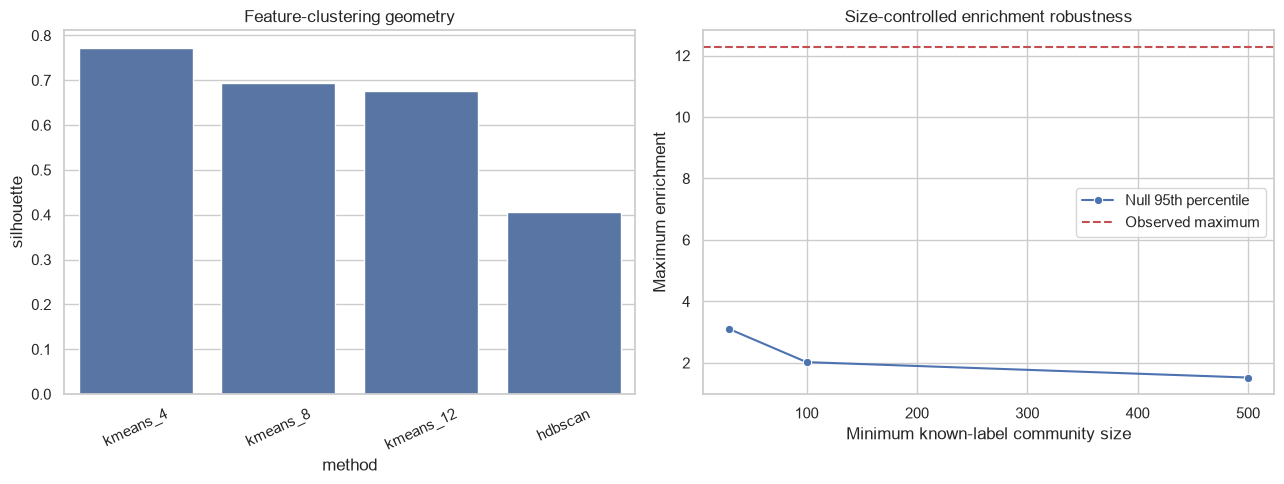

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.barplot(data=metrics, x='method', y='silhouette', color='#4c72b0', ax=axes[0])
axes[0].set_title('Feature-clustering geometry')
axes[0].tick_params(axis='x', rotation=25)
sns.lineplot(data=permutation, x='minimum_size', y='null_95_max_enrichment', marker='o', label='Null 95th percentile', ax=axes[1])
axes[1].axhline(12.278446, color='#c44e52', linestyle='--', label='Observed maximum')
axes[1].set_title('Size-controlled enrichment robustness')
axes[1].set_xlabel('Minimum known-label community size')
axes[1].set_ylabel('Maximum enrichment')
axes[1].legend()
fig.tight_layout()
fig.savefig(FIGURES / 'paper_results_summary.png', dpi=180, bbox_inches='tight')
plt.show()